# Human non-small cell lung cancer (NSCLC)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-02-02
> - Modified: 2025-12-21

---

# Experimental Design

> - Maynard A, et al. Therapy-Induced Evolution of Human Lung Cancer Revealed by Single-Cell RNA Sequencing. Cell. 2020 Sep 3;182(5):1232-1251.e22.
> - PRJNA591860
> - https://github.com/czbiohub-sf/scell_lung_adenocarcinoma

> - 49 samples (45 lung adenocarcinomas, 1 squamous cell carcinoma, and 3 tumor adjacent tissues), corresponding to 30 individual patients.
> - Smart-seq2
> - Illumina NextSeq or NovaSeq 6000
> - STAR-Hisat2
> - hg38

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/Hs_NSCLC_Smartseq2_PRJNA591860"

In [3]:
counts <- file.path(data_dir, "csv_files", "S01_datafinal.csv") |>
    data.table::fread(header = TRUE, nThread = 6) |>
    column_to_rownames("V1") |> 
    as.matrix() |>
    as("CsparseMatrix")

In [4]:
grepl("^ERCC-", rownames(counts)) |> table()


FALSE  TRUE 
26485    92 

In [5]:
erccs <- grep("^ERCC-", rownames(counts))
percent.ercc <- colSums(counts[erccs, ]) / colSums(counts)

In [6]:
counts <- counts[-erccs, ]

In [7]:
dim(counts)

[1] 26485 27489

In [8]:
metadata <- file.path(data_dir, "csv_files", "S01_metacells.csv") |>
    data.table::fread(header = TRUE, nThread = 6) |>
    column_to_rownames("V1") |> 
    column_to_rownames("cell_id")

In [9]:
dim(metadata)
colnames(metadata)

[1] 27489    40

[1] "well"                         "plate"                       
 [3] "sample_name"                  "patient_id"                  
 [5] "gender"                       "race"                        
 [7] "smokingHx"                    "histolgy"                    
 [9] "driver_gene"                  "driver_mutation"             
[11] "secondary_mutation"           "Notes"                       
[13] "stage.at.dx"                  "pathlogy_review"             
[15] "biopsy_date"                  "sort_date"                   
[17] "biopsy_type"                  "biopsy_site"                 
[19] "primary_or_metastaic"         "biopsy_time_status"          
[21] "early_treatment_status"       "best_response_status"        
[23] "biopsy_timing"                "analysis"                    
[25] "treatment_history"            "treatment_history_detail"    
[27] "line_of_therapy"              "treatment_type"              
[29] "treatment"                    "percent_PFS_ref_values"      
[31] "percent.PFS.reference.values" "infections"                  
[33] "early_bx_day"                 "treatment_start_date"        
[35] "pfs_over_under"               "pfs_day"                     
[37] "pfs_month"                    "date_of_death"               
[39] "stageIII.IV_ca_dx_date"       "ca_dx_OS"

In [10]:
scrna <- CreateSeuratObject(
    counts = counts, meta.data = metadata, project = "PBMCs")

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”


In [11]:
scrna <- AddMetaData(scrna, percent.ercc, col.name = "percent.ercc")

In [12]:
scrna

An object of class Seurat 
26485 features across 27489 samples within 1 assay 
Active assay: RNA (26485 features, 0 variable features)

# 2. Quality Control

## 1). Calculate Metrics

In [13]:
# Mitochondrial genes
mt <- "(?i)^MT-"
# scrna[["percent.mt"]] <- PercentageFeatureSet(scrna, pattern = mt)
scrna <- PercentageFeatureSet(
    scrna, pattern = mt, col.name = "percent.mt")

In [14]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna <- PercentageFeatureSet(
    scrna, pattern = rp, col.name = "percent.rp")

In [15]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

## 2). Visualizate Metrics

In [23]:
# Standard Seurat workflow (Seurat V5's function has set the random seed)
standard_preprocessing <- function(
    seurat, method = c("lognorm", "sctransform"), 
    ndim = 10, nfeatures = 2000, resolution = 0.5) {
    
    method <- match.arg(method)

    if (method == "lognorm") {
        # LogNormalize
        seurat <- NormalizeData(seurat, verbose = FALSE) |>
            FindVariableFeatures(nfeatures = nfeatures, verbose = FALSE) |>
            ScaleData(verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            # RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
    } else if (method == "sctransform") {
        # sctransform (very slow)
        seurat <- SCTransform(seurat, verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            # RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
    }
    return(seurat)
}

In [43]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)
sc.temp

An object of class Seurat 
26485 features across 27489 samples within 1 assay 
Active assay: RNA (26485 features, 2000 variable features)
 2 dimensional reductions calculated: pca, umap

Warning message:
“Removed 34 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 139 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 139 rows containing non-finite outside the scale range (`stat_ydensity()`).”


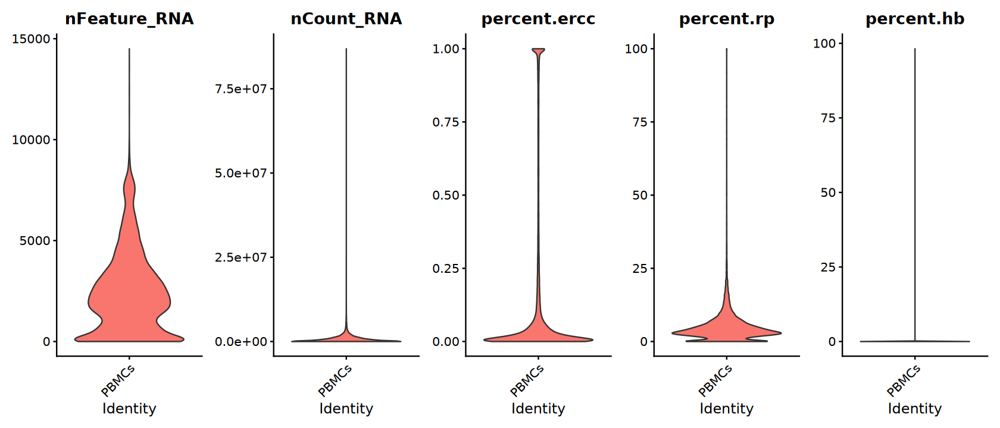

In [46]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, slot = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.ercc",
                     "percent.rp", "percent.hb"), 
        pt.size = 0, ncol = 5) + 
    NoLegend()

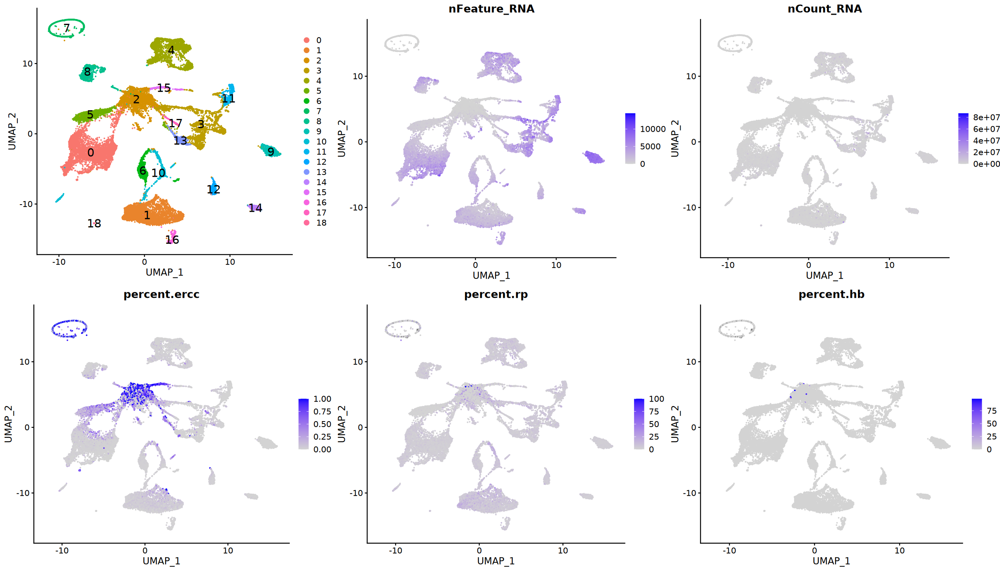

In [47]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, label.size = 6)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("nFeature_RNA", "nCount_RNA", "percent.ercc", 
                 "percent.rp", "percent.hb"),
    ncol = 3, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(p1, plotlist = p2, ncol = 3)

In [71]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.ercc")])

  nFeature_RNA     nCount_RNA        percent.ercc     
 Min.   :  201   Min.   :     372   Min.   :0.000000  
 1st Qu.: 1509   1st Qu.:  231646   1st Qu.:0.005458  
 Median : 2465   Median :  612098   Median :0.017880  
 Mean   : 2849   Mean   : 1063149   Mean   :0.067046  
 3rd Qu.: 3785   3rd Qu.: 1279999   3rd Qu.:0.053627  
 Max.   :14503   Max.   :86872336   Max.   :0.999255  

In [72]:
# Median Absolute Deviation (MAD)
calculate_mad_threshold <- function(
    metric, nmads = 3, log = FALSE) {
    
    if (log) metric <- log2(metric)
    
    median_x <- median(metric)
    mad_x <- mad(metric)
    
    lower_bound <- median_x - nmads * mad_x
    upper_bound <- median_x + nmads * mad_x
    
    if (log) {
        lower_bound <- 2^lower_bound
        upper_bound <- 2^upper_bound
    }
    
    return(c(lower_bound = round(lower_bound), 
             upper_bound = round(upper_bound)))
}

In [73]:
nCount_threshold <- calculate_mad_threshold(
    sc.temp$nCount_RNA, log = TRUE)
cat(sprintf("Counts: Upper: %d, Lower: %d\n", 
            nCount_threshold["upper_bound"], 
            nCount_threshold["lower_bound"]))

nFeature_threshold <- calculate_mad_threshold(
    sc.temp$nFeature_RNA, log = TRUE)
cat(sprintf("Features: Upper: %d, Lower: %d\n", 
            nFeature_threshold["upper_bound"], 
            nFeature_threshold["lower_bound"]))

Counts: Upper: 24727272, Lower: 15152
Features: Upper: 18861, Lower: 322


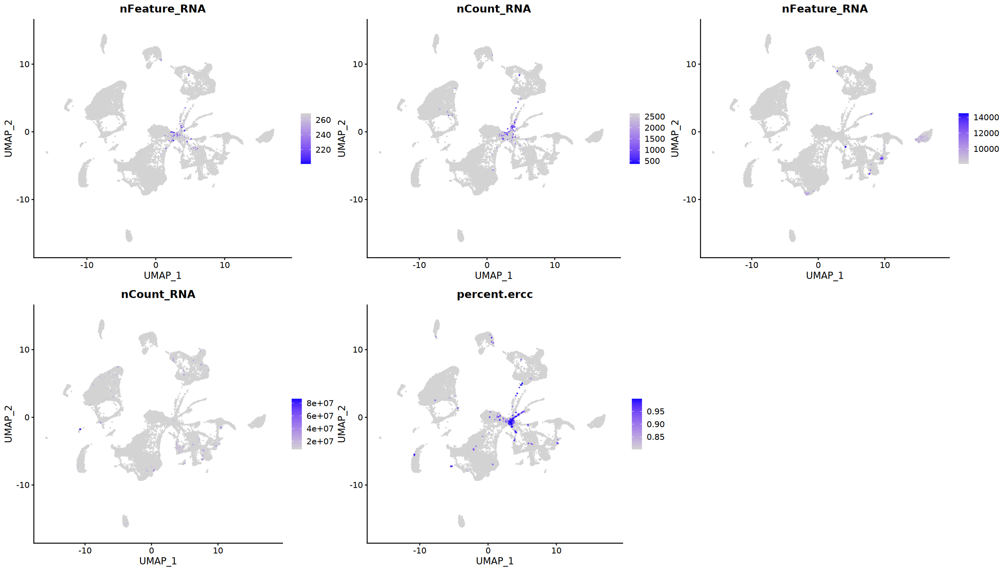

In [75]:
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", 
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"), 
    combine = FALSE)
p3 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("nFeature_RNA", "nCount_RNA", "percent.ercc"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p2, p3), ncol = 3, byrow = TRUE)

## 6). Filtering Low-quality Cells

In [76]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & 
        nCount_RNA > 50000)
scrna

An object of class Seurat 
26485 features across 21444 samples within 1 assay 
Active assay: RNA (26485 features, 0 variable features)

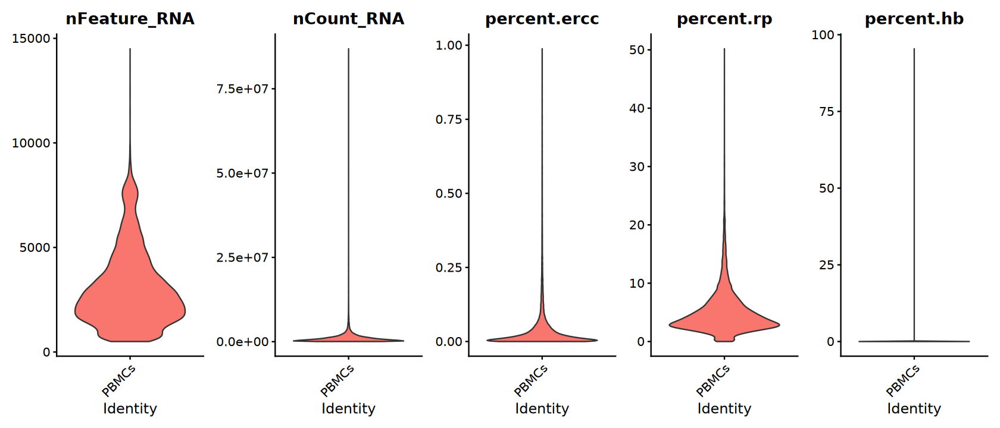

In [77]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, slot = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.ercc",
                     "percent.rp", "percent.hb"), 
        pt.size = 0, ncol = 5) + 
    NoLegend()

## 7). Evaluating Noise

### a). Cell cycle effect

Seurat suggest regressing out the difference between the G2M and S phase scores. This means that signals separating non-cycling cells and cycling cells will be maintained, but differences in cell cycle phase among proliferating cells will be regressed out of the data.

```R
scrna$CC.Difference <- scrna$S.Score - scrna$G2M.Score
scrna <- ScaleData(scrna, features = Features(scrna), vars.to.regress = "CC.Difference", verbose = FALSE)
```

In [78]:
str(cc.genes)

List of 2
 $ s.genes  : chr [1:43] "MCM5" "PCNA" "TYMS" "FEN1" ...
 $ g2m.genes: chr [1:54] "HMGB2" "CDK1" "NUSAP1" "UBE2C" ...


In [79]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”


### b). Cell dissociation effect

- van den Brink, S., Sage, F., Vértesy, Á. et al. Single-cell sequencing reveals dissociation-induced gene expression in tissue subpopulations. Nat Methods 14, 935–936 (2017). https://doi.org/10.1038/nmeth.4437

In [80]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")
str(dissociation_genes)

 chr [1:140] "Actg1" "Btg1" "Cxcl1" "Dnajb4" "Errfi1" "H3f3b" "Hspb1" ...


In [81]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(
        dissociationGenes = toupper(dissociation_genes)))
# rename
scrna@meta.data <- scrna@meta.data |> 
    dplyr::rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: MT1, MT2, CCRN4L, not searching for symbol synonyms”


## 8). Visualization

In [82]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)

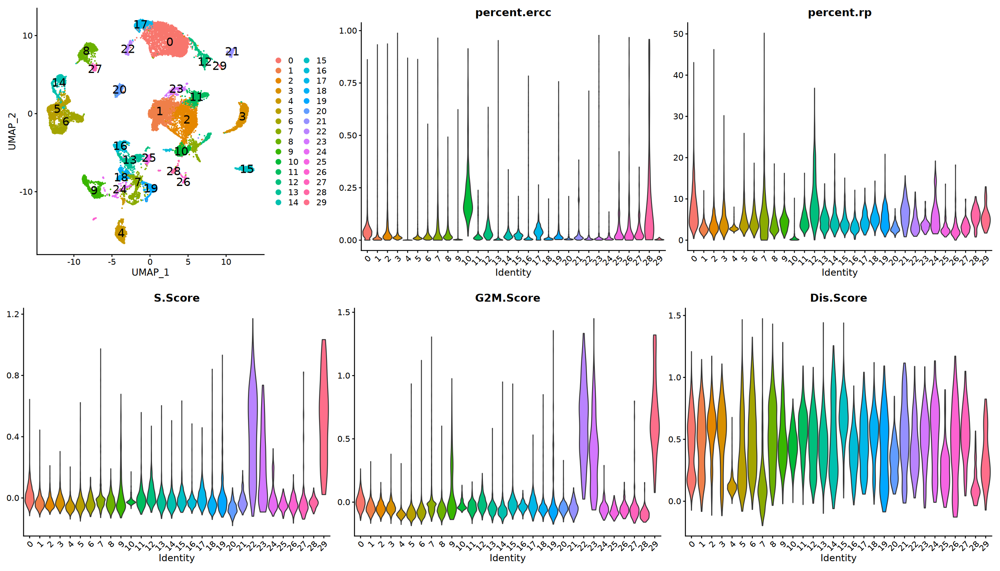

In [83]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", 
    label = TRUE, label.size = 6)
p2 <- VlnPlot(
    sc.temp, features = c("percent.ercc", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, ncol = 2)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, ncol = 3)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 2)),
          p3, ncol = 1)

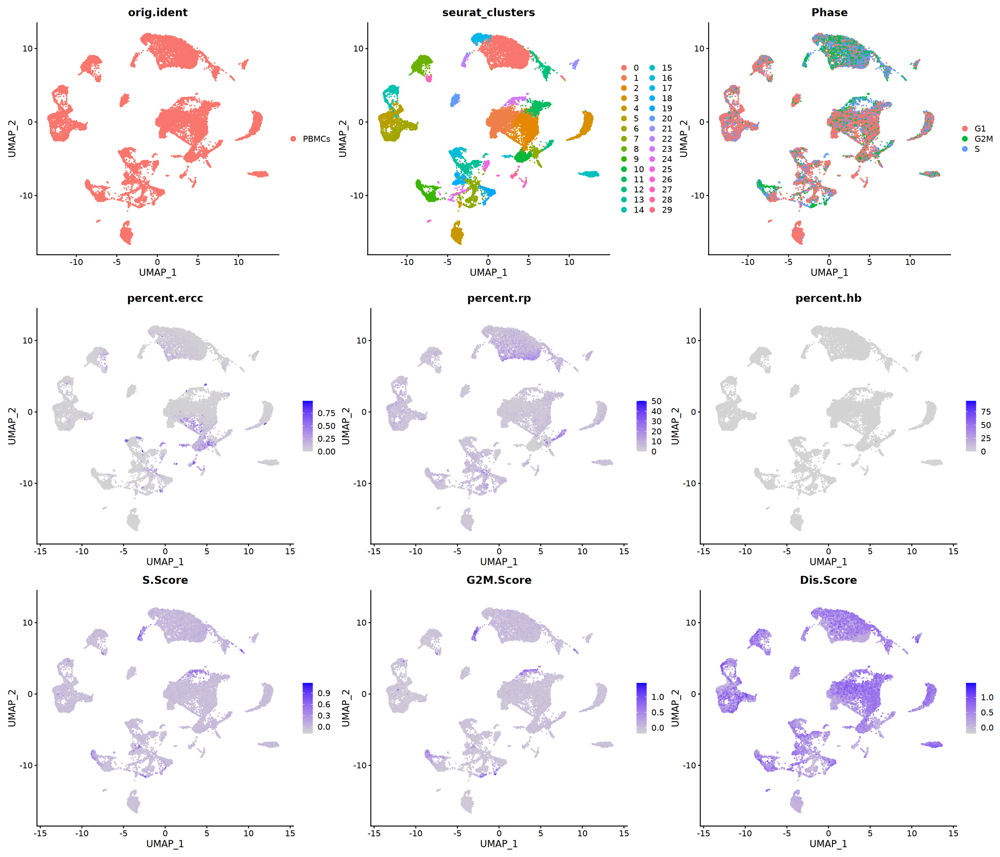

In [84]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", ncol = 3,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", ncol = 3,
    features = c("percent.ercc", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 1, rel_heights = c(1, 2))

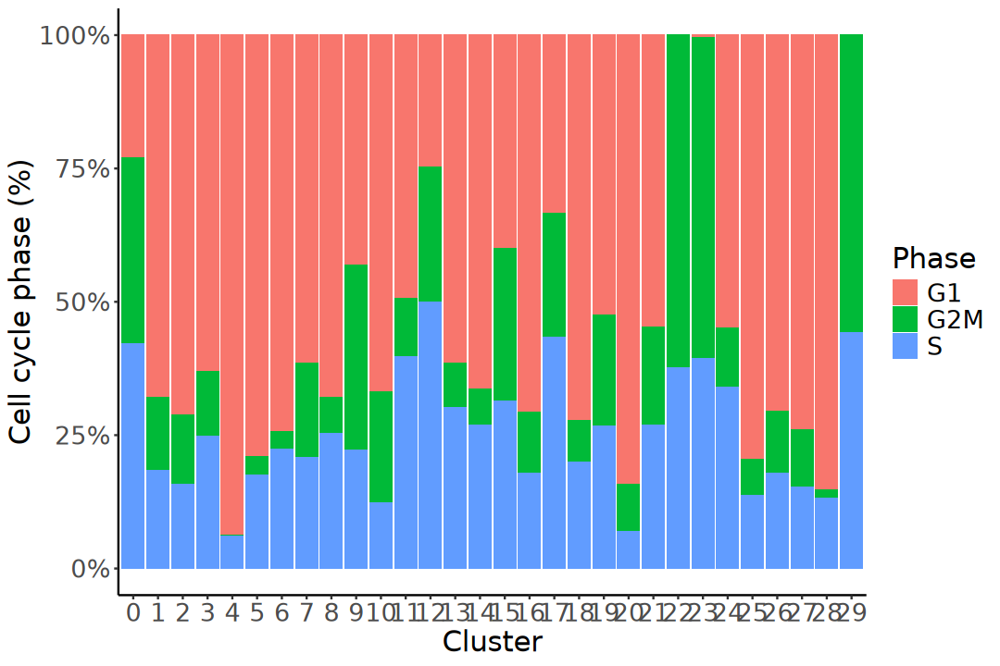

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", 
             fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [87]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("percent.ercc", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

In [89]:
cors

,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10
percent.ercc,0.121821345,0.082444575,-0.023515775,-0.11205092,-0.0197541323,0.155905830,-0.076367998,0.0986216787,-0.20462437,-0.17326723
percent.rp,0.098538176,0.093884602,0.119365722,0.24886306,0.0672895844,0.052417772,-0.053597967,0.0361230057,-0.10364553,-0.08656817
percent.hb,0.005491621,0.003287308,-0.002160073,-0.01159947,-0.0002939175,0.007988871,-0.004823337,0.0070242942,-0.02246159,-0.01438925
S.Score,0.167318889,0.082243025,0.051720029,0.24568229,0.0604578957,-0.171174281,0.070104380,-0.0006292857,0.14458948,0.03198885
G2M.Score,0.221246537,0.030287403,0.064415173,0.18026475,0.0593744882,-0.206180470,0.089954035,0.0322801980,0.12280479,-0.01186954
Dis.Score,0.026511552,0.192026011,0.005707926,-0.08877946,-0.0916662043,0.057106455,-0.006175436,-0.0418786531,0.08606695,0.18135912


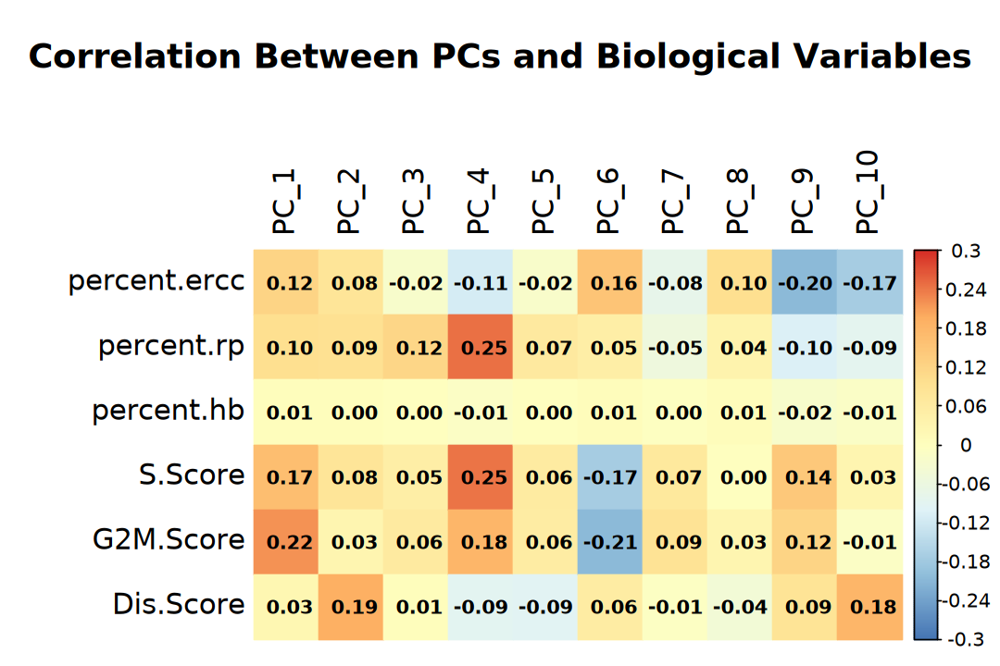

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, col.lim = c(-0.3, 0.3),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.8, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 5, 0))

# 3. Normalization

In [92]:
scrna

An object of class Seurat 
26485 features across 21444 samples within 1 assay 
Active assay: RNA (26485 features, 0 variable features)

In [93]:
scrna <- NormalizeData(scrna, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 2000, verbose = FALSE) |>
    ScaleData(verbose = FALSE)

In [94]:
scrna

An object of class Seurat 
26485 features across 21444 samples within 1 assay 
Active assay: RNA (26485 features, 2000 variable features)

# 4. Dimensionality Reduction

In [95]:
scrna <- RunPCA(
    scrna, features = VariableFeatures(scrna), 
    npcs = 50, verbose = FALSE)

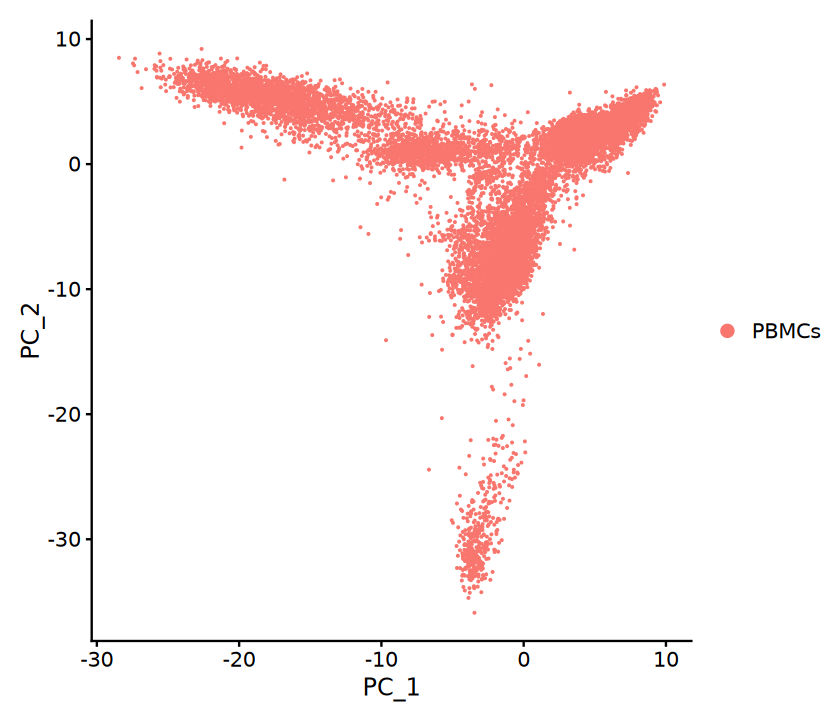

In [96]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca")

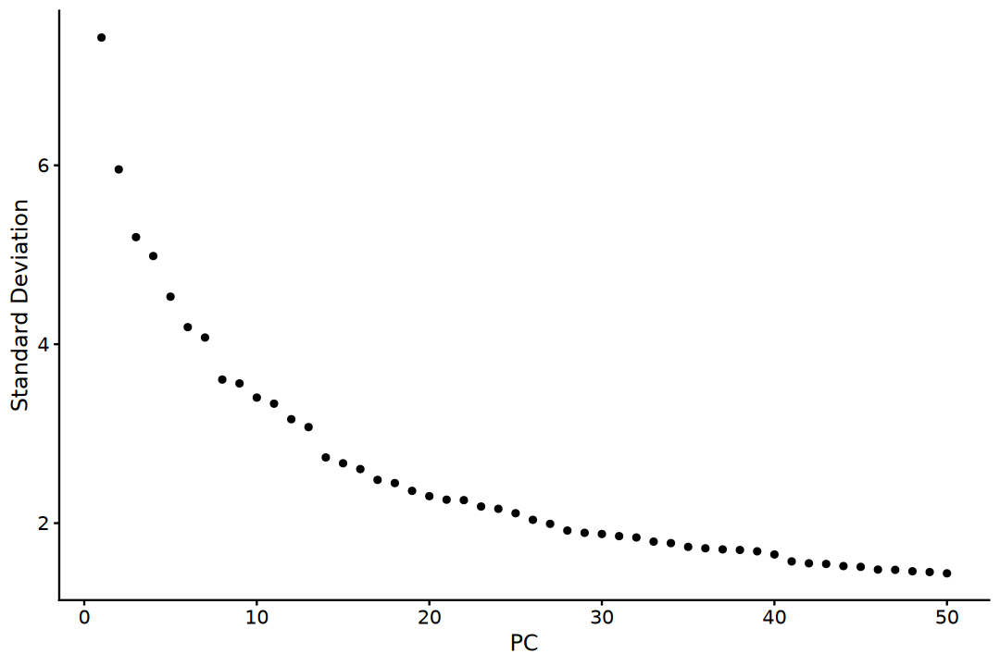

In [97]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [98]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 34


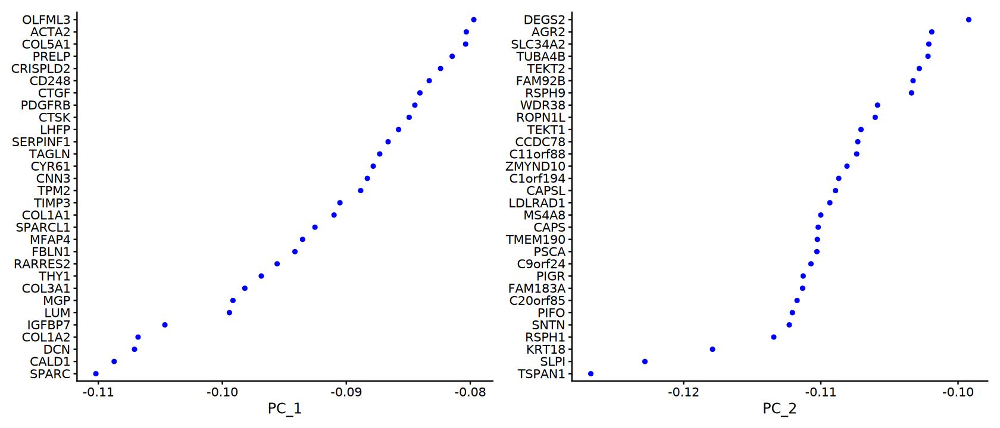

In [99]:
# Gene information
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(scrna, dims = 1:2, reduction = "pca", ncol = 2)

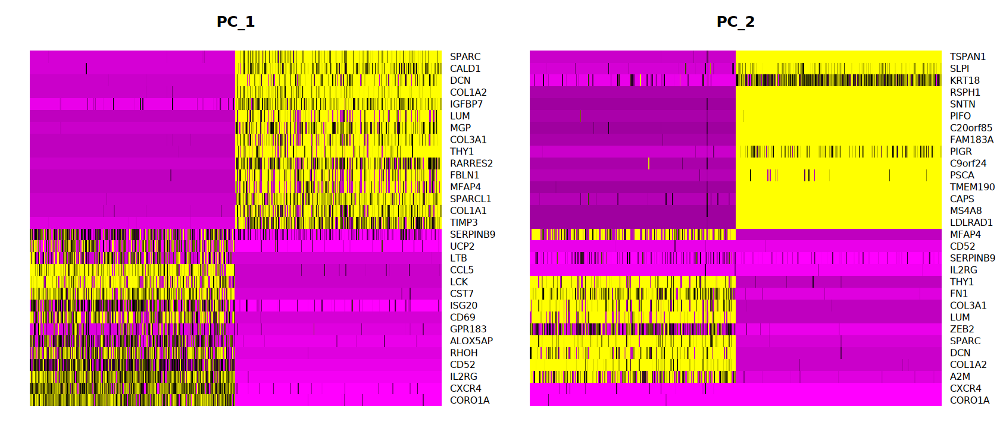

In [100]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(scrna, dims = 1:2, cells = 500, balanced = TRUE)

In [101]:
npcs_clusters <- function (
    obj, method = c("umap", "tsne"), reduction, 
    dims = c(10, 20, 25, 30, 40, 50), resolution = 0.5) {

    method <- match.arg(method)
    plot_list <- list()
    
    for (dim in dims) {
        obj <- FindNeighbors(
            obj, reduction = reduction, dims = 1:dim, verbose = FALSE)
        obj <- FindClusters(
            obj, resolution = resolution, verbose = FALSE)
        if (method == "umap") {
            # UMAP
            obj <- RunUMAP(
                obj, dims = 1:dim, reduction = reduction, verbose = FALSE)
            plot_list[[paste0("nPCs_", dim)]] <- DimPlot(
                obj, reduction = "umap", group.by = "seurat_clusters", 
                label = TRUE, label.size = 6, repel = FALSE) +
                ggtitle(paste0("UMAP, nPCs = ", dim))
        } else if (method == "tsne") {
            # t-SNE
            obj <- RunTSNE(
                obj, dims = 1:dim, reduction = reduction, verbose = FALSE)
            plot_list[[paste0("nPCs_", dim)]] <- DimPlot(
                obj, reduction = "tsne", group.by = "seurat_clusters", 
                label = TRUE, label.size = 6, repel = FALSE) +
                ggtitle(paste0("t-SNE, nPCs = ", dim))
        }
    }
    return(plot_list)
}

In [102]:
plot_list <- npcs_clusters(
    scrna, method = "umap", reduction = "pca")

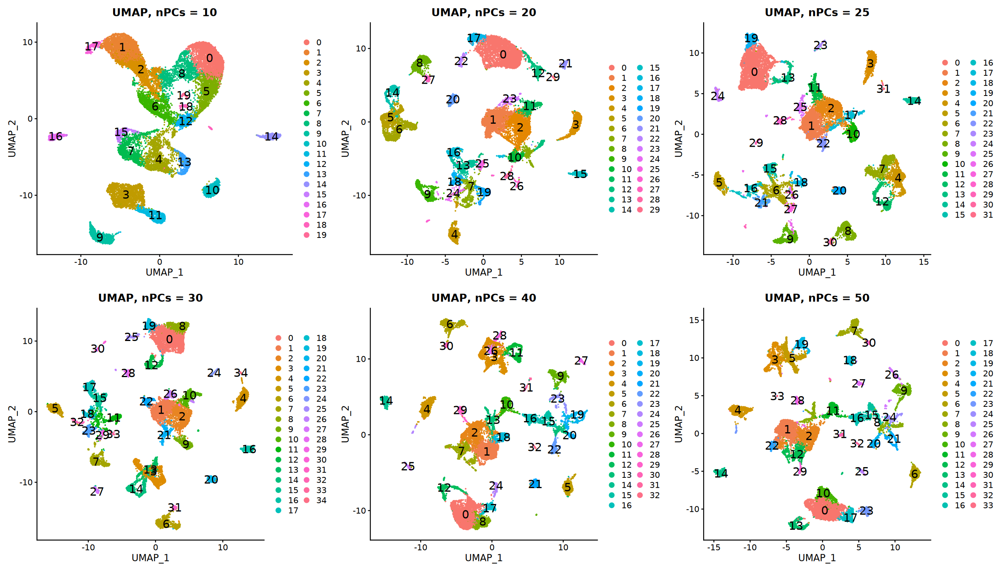

In [103]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plot_list, ncol = 3)

In [104]:
nPCs <- 30

# 5. Integration (Skip)

# 6. Clustering

In [108]:
scrna <- FindNeighbors(
    scrna, features = VariableFeatures(scrna), k.param = 30,
    reduction = "pca", dims = 1:nPCs, verbose = FALSE)

In [109]:
scrna <- FindClusters(scrna, resolution = 0.5, verbose = FALSE)

In [110]:
scrna <- RunUMAP(
    scrna, dims = 1:nPCs, reduction = "pca",
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [111]:
scrna <- RunTSNE(
    scrna, dims = 1:nPCs, reduction = "pca", 
    perplexity = 30, verbose = FALSE)

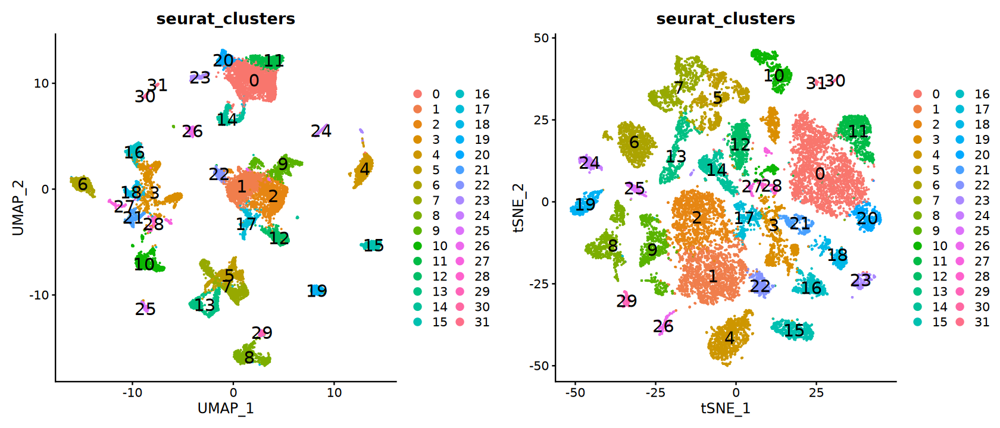

In [112]:
p1 <- DimPlot(
    scrna, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

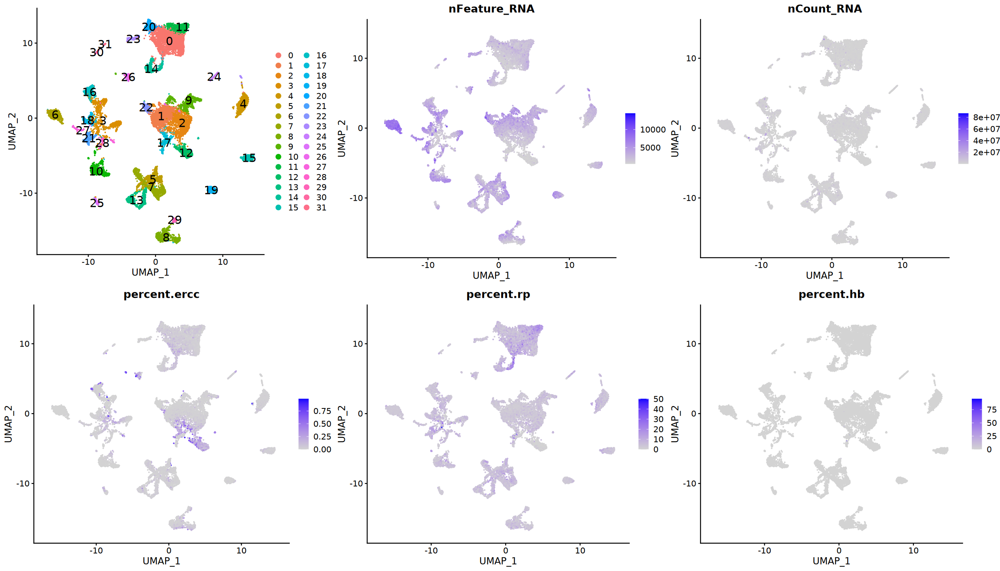

In [113]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, label.size = 6)
p2 <- FeaturePlot(
    scrna, reduction = "umap",
    features = c("nFeature_RNA", "nCount_RNA", "percent.ercc", 
                 "percent.rp", "percent.hb"),
    ncol = 3, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(p1, plotlist = p2, ncol = 3)

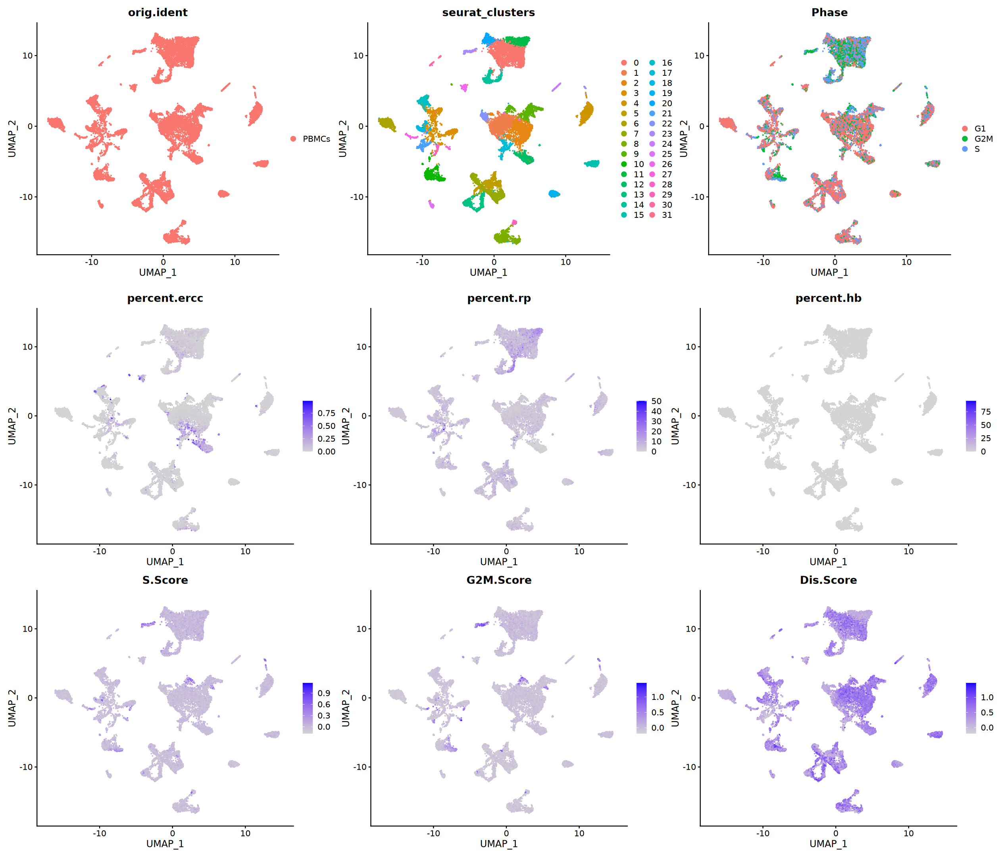

In [114]:
p1 <- DimPlot(
    scrna, reduction = "umap", ncol = 3,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    scrna, reduction = "umap", ncol = 3,
    features = c("percent.ercc", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 1, rel_heights = c(1, 2))

In [115]:
scrna

An object of class Seurat 
26485 features across 21444 samples within 1 assay 
Active assay: RNA (26485 features, 2000 variable features)
 3 dimensional reductions calculated: pca, umap, tsne

# 7. Cluster Biomarkers

## Marker Identification

In [105]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = FALSE, verbose = FALSE)

In [106]:
head(sc.markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
S100A12,0,6.227404,0.958,0.075,0,0,S100A12
VCAN,0,5.421164,0.989,0.119,0,0,VCAN
CD14,0,4.547182,0.965,0.095,0,0,CD14
MS4A6A,0,3.666521,0.982,0.120,0,0,MS4A6A
AC020656.1,0,4.142428,0.984,0.125,0,0,AC020656.1
CSTA,0,3.892278,0.978,0.123,0,0,CSTA


In [108]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [109]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11
length(gene),1404,76,112,119,2000,129,234,159,209,162,106,307


In [110]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

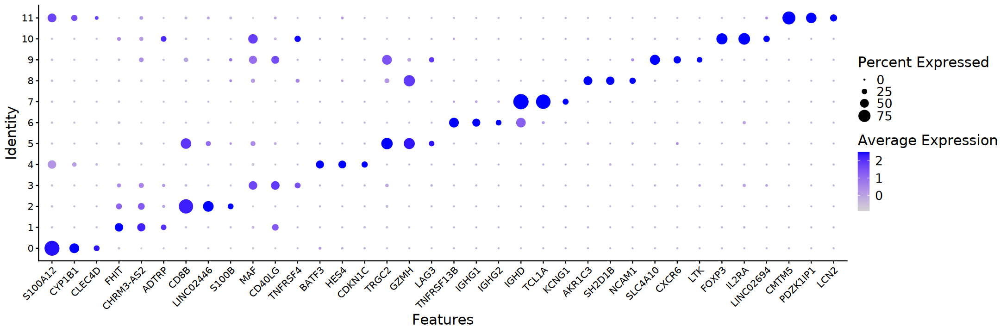

In [111]:
options(repr.plot.width = 18, repr.plot.height = 6)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [112]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [113]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(scrna, features = top10$gene[index])
    p2 <- FeaturePlot(
        scrna, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        scrna, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

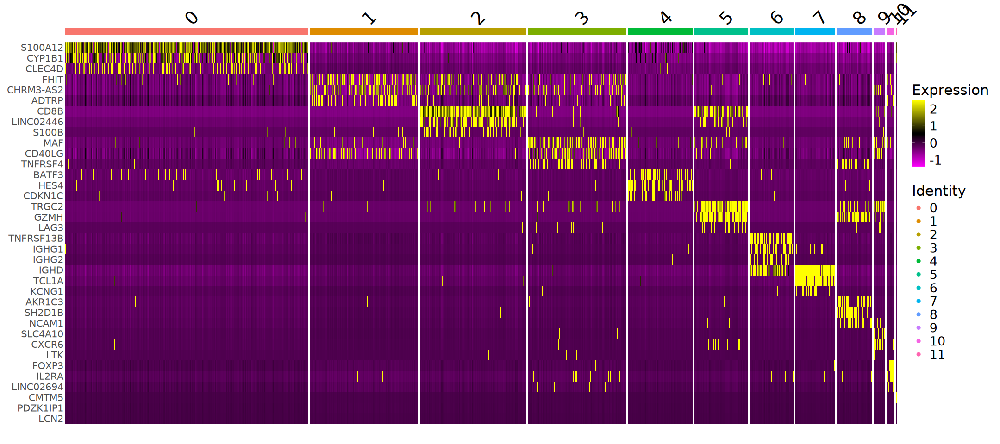

In [114]:
options(repr.plot.width = 18, repr.plot.height = 8)
DoHeatmap(scrna, slot = "scale.data", 
          features = top3$gene, size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [115]:
saveRDS(scrna, file.path(
    data_dir, "result", "s7_cluster_seurat_V5.rds"))

# 8. Cell-type Annotation

Picking joint bandwidth of 0.0702

Picking joint bandwidth of 0.0218

Picking joint bandwidth of 0.0148

Picking joint bandwidth of 0.222

Picking joint bandwidth of 0.051

Picking joint bandwidth of 0.0637



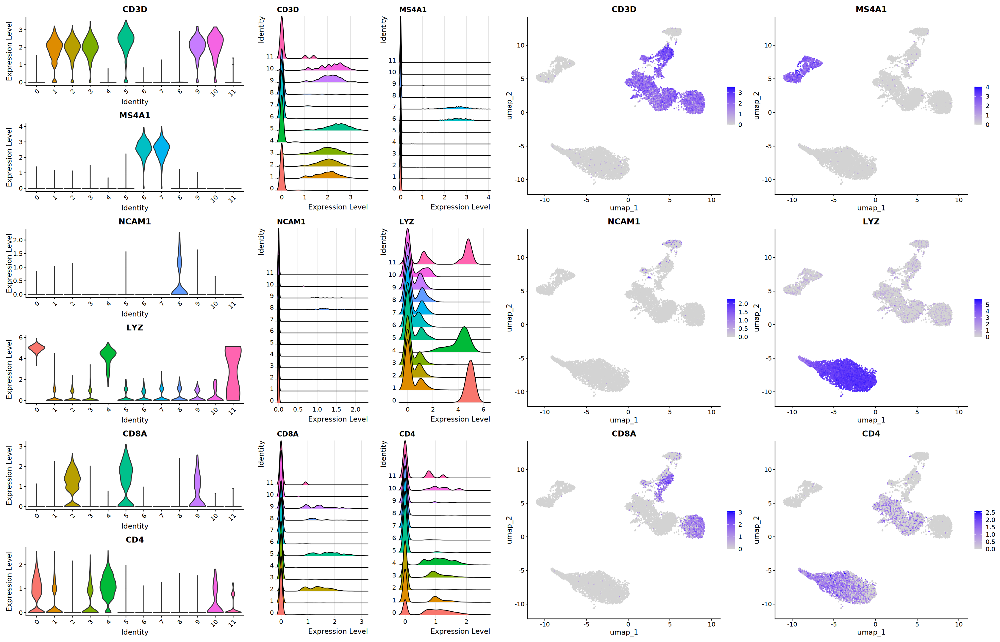

In [107]:
geneset <- c("CD3D", "MS4A1", "NCAM1", "LYZ", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    scrna, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

## Manual Annotation

### Marker genes

In [116]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [117]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "S100A8", "S100A9", "CYP1B1", "THBS1", "S1PR3", "CRISPLD2", "STEAP4", "CLEC4D", "MCEMP1"
cluster_1: "CCR7", "LEF1", "FHIT", "TRABD2A", "CHRM3-AS2", "ADTRP", "TRAT1", "CD40LG", "LINC01550", "FBLN5"
cluster_2: "CD8B", "CD8A", "KLRK1", "LINC02446", "NELL2", "LRRN3", "S100B", "PASK", "PDE3B", "SCGB3A1"
cluster_3: "AQP3", "GPR183", "INPP4B", "MAF", "CD40LG", "TNFRSF4", "CD28", "GATA3", "SLAMF1", "ANK3"
cluster_4: "TCF7L2", "BATF3", "HES4", "CTSL", "SASH1", "CDKN1C", "CLEC10A", "CXCL10", "IL3RA", "AC064805.1"
cluster_5: "CCL5", "KLRG1", "TRGC2", "GZMH", "LINC01871", "FCRL6", "GZMK", "LAG3", "A2M-AS1", "EOMES"
cluster_6: "TNFRSF13B", "JCHAIN", "LINC01857", "IGHA1", "IGHG1", "CPNE5", "IGHG3", "LINC01781", "PPP1R14A", "IGHG2"
cluster_7: "IGHD", "TCL1A", "FCER2", "FCRL1", "LINC02397", "TSPAN13", "COL19A1", "CD200", "PCDH9", "KCNG1"
cluster_8: "KLRF1", "GZMB", "SPON2", "CLIC3", "AKR1C3", "SH2D1B", "NMUR1", "NCR1", "NCAM1", "RNF165"
cluster_9: "GZMK", "SLC4A10", "CXCR6", "AC1

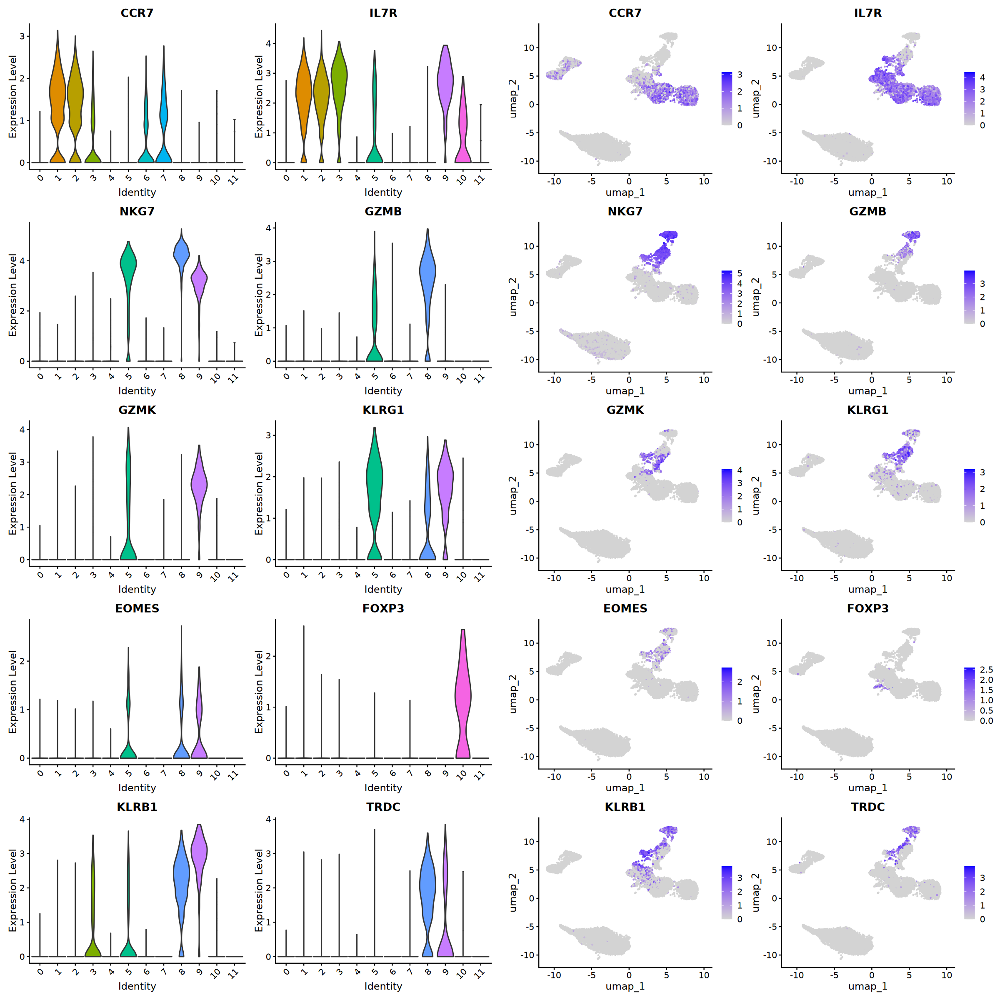

In [118]:
geneset <- c("CCR7", "IL7R", "NKG7", "GZMB", "GZMK",
             "KLRG1", "EOMES", "FOXP3", "KLRB1", "TRDC")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 2, pt.size = 0)
p2 <- FeaturePlot(
    scrna, features = geneset, reduction = "umap", ncol = 2)

options(repr.plot.width = 20, repr.plot.height = 20)
plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 1))

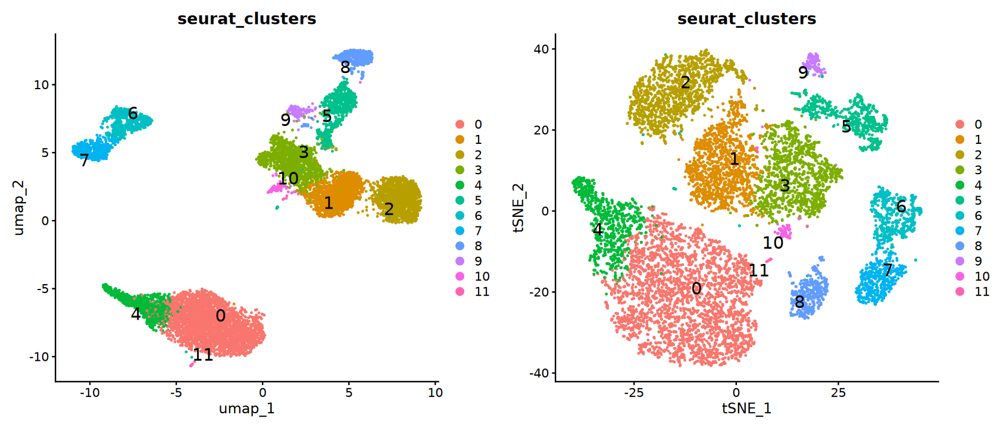

In [119]:
p1 <- DimPlot(
    scrna, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = TRUE)
p2 <- DimPlot(
    scrna, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

#### AI modes

In [120]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Monocytes",
    "1" = "Naïve CD4 T",
    "2" = "Naïve CD8 T",
    "3" = "Activated CD4 T",
    "4" = "Dendritic Cells",
    "5" = "Cytotoxic CD8",
    "6" = "Plasma Cells",
    "7" = "Naive B",
    "8" = "NK Cells",
    "9" = "MAIT",
    "10" = "Treg", 
    "11" = "Platelets")

In [121]:
scrna@meta.data$ChatGPT_Anno <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]
# Idents(scrna) <- scrna$seurat_clusters
# scrna <- RenameIdents(scrna, cluster2celltype)

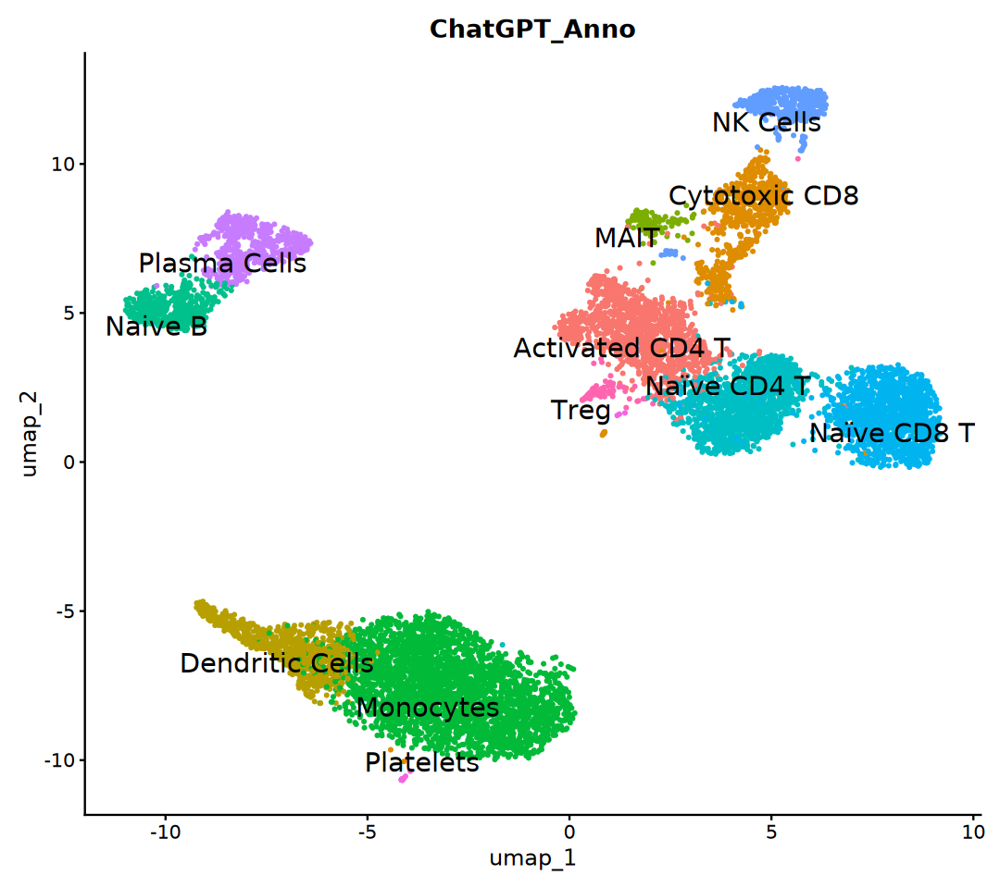

In [122]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(scrna, reduction = "umap", group.by = "ChatGPT_Anno", 
        label = TRUE, repel = TRUE,
        pt.size = 0.5, label.size = 6) + 
    NoLegend()